# 02 · Segmentación de clientes: K-Means + SVM

**Pregunta de negocio:** ¿qué tipos de clientes tengo y cómo cambian con el tiempo?

**Enfoque en dos pasos**, como funcionaría dentro del SaaS:

1. **Descubrir** los segmentos con *clustering* (K-Means) en una fecha de entrenamiento
   (30-sep-2017). Aquí se decide cuántos grupos hay y qué significa cada uno.
2. **Asignar** cada cliente a un segmento con un **SVM** entrenado sobre esas etiquetas.
   Cada mes llegan datos nuevos: volver a clusterizar movería las fronteras y cambiaría
   el significado de los grupos (el "cluster 2" de hoy no es el de mañana). El SVM
   mantiene fijas las definiciones, asigna en milisegundos y da una confianza por cliente.

Al final se aplica el SVM al 31-dic y se mide **cuántos clientes cambiaron de segmento**,
que es la información accionable para el negocio.

In [1]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    adjusted_rand_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split

from brujula_ml import datos
from brujula_ml import features as F
from brujula_ml import graficos as G
from brujula_ml import segmentacion as S
from brujula_ml.rutas import MODELOS, PROCESADOS

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.2f}".format)
G.estilo()

CORTE_ENTRENAMIENTO = pd.Timestamp("2017-09-30")

tx = F.transacciones()
c = F.cestas(tx)
camp = F.campanas()
f_ent = F.features_en(c, CORTE_ENTRENAMIENTO, camp)
f_fin = F.features_en(c, F.FIN, camp)
X_ent = S.matriz(f_ent)
print(
    f"Hogares al {CORTE_ENTRENAMIENTO.date()}: {len(f_ent):,}   ·   al {F.FIN.date()}: {len(f_fin):,}"
)

Hogares al 2017-09-30: 2,446   ·   al 2017-12-31: 2,469


## 1. Variables

Se segmenta con cinco variables de **ciclo de vida y valor**, porque son las que responden
la pregunta del negocio ("¿quién compra mucho?, ¿quién se está yendo?"):

| Variable | Qué mide |
|---|---|
| `recencia_dias` | días desde la última compra |
| `cestas_365` | compras en los últimos 12 meses |
| `gasto_365` | gasto en los últimos 12 meses |
| `ticket_medio` | gasto por compra (últimos 180 días) |
| `tendencia_90` | compras de los últimos 90 días ÷ los 90 anteriores |

Todas tienen cola larga → `log1p` y estandarización (`segmentacion.preprocesador`). La
mezcla de departamentos y la demografía **no** forman los grupos: se usan después para
describirlos.

In [2]:
X_ent.describe(percentiles=[0.1, 0.5, 0.9]).T

,count,mean,std,min,10%,50%,90%,max
recencia_dias,"2,446.00",19.29,36.69,0.00,0.00,6.00,55.00,267.00
cestas_365,"2,446.00",47.71,54.70,1.00,6.00,32.00,103.00,730.00
gasto_365,"2,446.00","1,389.74","1,526.86",2.00,122.41,899.18,"3,328.48","17,939.63"
ticket_medio,"2,446.00",31.21,21.93,1.00,10.32,26.13,56.54,208.77
tendencia_90,"2,446.00",1.34,1.89,0.03,0.47,1.00,2.09,58.00


## 2. ¿Cuántos segmentos?

,inercia,silhouette,davies_bouldin,calinski_harabasz,bic_gmm
k,,,,,
2,"8,116.82",0.33,1.28,"1,238.49","21,583.70"
3,"6,822.02",0.33,1.27,968.31,"21,224.92"
4,"5,792.03",0.24,1.29,904.78,"21,029.57"
5,"5,090.95",0.23,1.21,855.75,"21,004.93"
6,"4,613.77",0.21,1.29,805.59,"17,054.54"
7,"4,299.35",0.20,1.27,749.84,"17,003.97"
8,"4,010.00",0.20,1.26,713.95,"16,786.89"


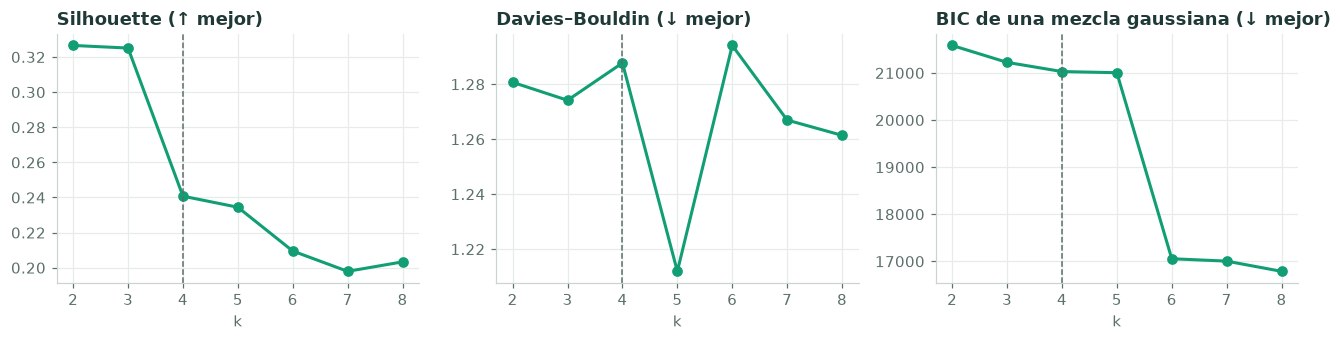

In [3]:
Z = S.preprocesador().fit_transform(X_ent)
evaluacion = S.evaluar_k(Z)
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, titulo, mejor in [
    (ejes[0], "silhouette", "Silhouette (↑ mejor)", "max"),
    (ejes[1], "davies_bouldin", "Davies–Bouldin (↓ mejor)", "min"),
    (ejes[2], "bic_gmm", "BIC de una mezcla gaussiana (↓ mejor)", "min"),
]:
    ax.plot(evaluacion.index, evaluacion[col], marker="o", color=G.MARCA, lw=2)
    ax.axvline(4, color=G.TINTA_2, ls="--", lw=1)
    ax.set(title=titulo, xlabel="k")
fig.tight_layout()
G.guardar(fig, "02_eleccion_k")
evaluacion

In [4]:
estab = pd.DataFrame({k: S.estabilidad(Z, k, replicas=20) for k in (3, 4, 5)})
estab.describe().loc[["mean", "min"]].rename(index={"mean": "ARI medio", "min": "ARI mínimo"})

,3,4,5
ARI medio,0.90,0.86,0.69
ARI mínimo,0.40,0.60,0.45


**Lectura honesta de las métricas.** Ninguna métrica interna da un "k" indiscutible, algo
habitual con datos de comportamiento, que forman un continuo más que grupos separados. El
silhouette favorece k=2–3, y el BIC de la mezcla gaussiana sigue bajando con k (con un salto
en k=6), así que tampoco marca un tamaño natural.

Se elige **k = 4** porque:

- es estable: ARI medio de 0,86 entre remuestreos bootstrap (k=3 llega a 0,90);
- con k=3, los clientes que compran con regularidad pero **están bajando el ritmo** quedan
  mezclados con los fieles en un solo grupo de ~1.460 hogares. k=4 los separa como
  *En riesgo*, el grupo más accionable para una campaña de retención;
- es el número de segmentos con el que trabaja el producto.

## 3. Perfil y nombre de cada segmento

K-Means devuelve números (0, 1, 2, 3). Para ponerles nombre de forma reproducible, cada
centroide se compara con un **arquetipo** (p. ej. *Dormidos* = recencia alta, poca compra) y
se resuelve la asignación óptima con el algoritmo húngaro (`segmentacion.nombrar`). Los
arquetipos solo nombran; no influyen en cómo se forman los grupos.

In [5]:
segmentador = S.Segmentador(k=4).fit(f_ent)
seg_ent = segmentador.predict(f_ent)

centros = pd.DataFrame(segmentador.kmeans_.cluster_centers_, columns=S.COLUMNAS)
centros.index = [G.NOMBRE[segmentador.nombres_[i]] for i in centros.index]
perfil = (
    f_ent[S.COLUMNAS]
    .assign(segmento=seg_ent.map(G.NOMBRE))
    .groupby("segmento")
    .median()
    .reindex([G.NOMBRE[s] for s in S.SEGMENTOS])
)
perfil["hogares"] = seg_ent.map(G.NOMBRE).value_counts()
perfil["% hogares"] = perfil["hogares"] / perfil["hogares"].sum() * 100
perfil["% venta 12m"] = (
    f_ent["gasto_365"].groupby(seg_ent.map(G.NOMBRE)).sum() / f_ent["gasto_365"].sum() * 100
)
perfil

,recencia_dias,cestas_365,gasto_365,ticket_medio,tendencia_90,hogares,% hogares,% venta 12m
segmento,,,,,,,,
Fieles,1.00,67.00,"1,983.39",28.25,1.00,1041,42.56,74.59
Prometedores,5.00,15.00,349.25,23.39,3.00,233,9.53,3.14
En riesgo,12.00,24.00,733.89,33.36,0.82,741,30.29,20.54
Dormidos,39.00,8.00,122.78,13.14,1.00,431,17.62,1.72


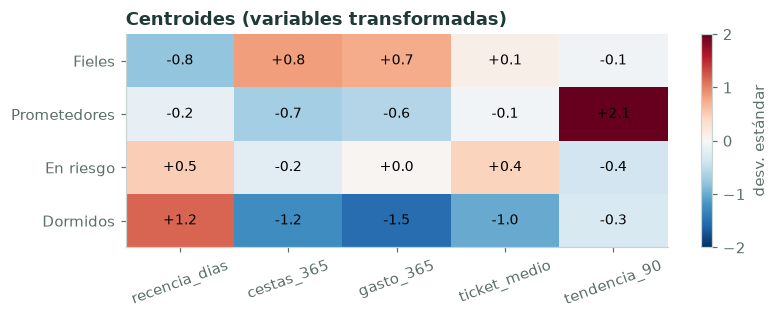

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3))
orden = [G.NOMBRE[s] for s in S.SEGMENTOS]
im = ax.imshow(centros.loc[orden].to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(S.COLUMNAS)), S.COLUMNAS, rotation=20)
ax.set_yticks(range(4), orden)
ax.grid(False)
for i in range(4):
    for j in range(len(S.COLUMNAS)):
        ax.text(j, i, f"{centros.loc[orden].iat[i, j]:+.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="desv. estándar")
ax.set_title("Centroides (variables transformadas)")
fig.tight_layout()

| Segmento | Lectura | Acción sugerida |
|---|---|---|
| **Fieles** | compran casi a diario, la mayor parte de la venta | cuidar: programas de lealtad, no regalar margen |
| **Prometedores** | compran poco aún, pero su ritmo se dispara (tendencia alta) | acompañar: ofertas de segunda y tercera compra |
| **En riesgo** | compran con regularidad, pero el ritmo cae | retener: contacto personalizado antes de que se vayan |
| **Dormidos** | hace semanas que no vienen y compraban poco | reactivar con una oferta fuerte, o no invertir |

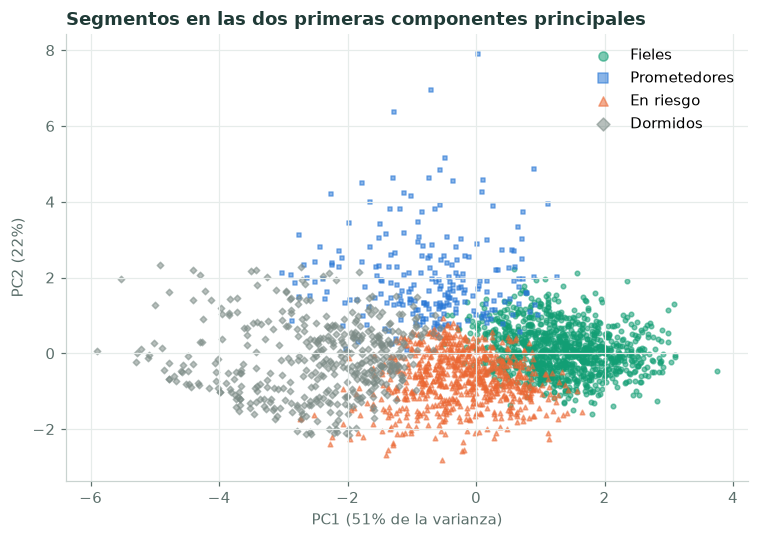

In [7]:
pca = PCA(2, random_state=0).fit(Z)
P2 = pca.transform(Z)
fig, ax = plt.subplots(figsize=(7, 5))
for s in S.SEGMENTOS:
    m = (seg_ent == s).to_numpy()
    ax.scatter(
        P2[m, 0], P2[m, 1], s=9, alpha=0.55, c=G.COLOR[s], marker=G.FORMA[s], label=G.NOMBRE[s]
    )
ax.set(
    title="Segmentos en las dos primeras componentes principales",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
)
ax.legend(markerscale=2)
fig.tight_layout()
G.guardar(fig, "02_segmentos_pca")

### ¿Quiénes son? Departamentos y demografía

Los segmentos se diferencian por **cuánto y cuándo** compran, no tanto por **qué**: la cesta
es parecida en todos (~50 % abarrotes). La excepción son los *Fieles*, que compran bastante
más combustible: la gasolinera actúa como ancla de la visita frecuente.

In [8]:
dep = (
    tx[tx["fecha"] <= CORTE_ENTRENAMIENTO]
    .assign(segmento=lambda d: d["household_id"].map(seg_ent).map(G.NOMBRE))
    .pivot_table(index="segmento", columns="department", values="sales_value", aggfunc="sum")
)
principales = dep.sum().sort_values(ascending=False).index[:8]
mezcla = dep[principales].div(dep.sum(axis=1), axis=0) * 100
mezcla.reindex(orden).round(1)

department,GROCERY,DRUG GM,FUEL,PRODUCE,MEAT,MEAT-PCKGD,DELI,MISCELLANEOUS
segmento,,,,,,,,
Fieles,49.50,12.80,8.50,7.00,6.50,5.00,3.20,1.90
Prometedores,51.00,12.50,4.80,7.20,7.00,6.10,3.50,1.00
En riesgo,52.40,12.40,4.30,7.80,7.50,5.90,3.20,0.70
Dormidos,51.90,13.70,4.70,6.70,5.80,4.70,3.30,1.10


In [9]:
demo = datos.cargar("demographics").set_index("household_id")
demo["segmento"] = seg_ent.map(G.NOMBRE)
demo = demo.dropna(subset=["segmento"])
pd.concat(
    {
        "con hijos (%)": demo.groupby("segmento")["kids_count"].apply(
            lambda s: (s.isin(["1", "2", "3+"])).mean() * 100
        ),
        "65+ años (%)": demo.groupby("segmento")["age"].apply(lambda s: (s == "65+").mean() * 100),
        "ingreso ≥ 75K (%)": demo.groupby("segmento")["income"].apply(
            lambda s: (
                s.isin(
                    ["75-99K", "100-124K", "125-149K", "150-174K", "175-199K", "200-249K", "250K+"]
                ).mean()
                * 100
            )
        ),
        "hogares con demografía": demo.groupby("segmento").size(),
    },
    axis=1,
).reindex(orden)

,con hijos (%),65+ años (%),ingreso ≥ 75K (%),hogares con demografía
segmento,,,,
Fieles,33.60,7.79,27.27,616
Prometedores,46.67,13.33,30.00,30
En riesgo,43.62,12.08,31.54,149
Dormidos,33.33,33.33,16.67,6


Ojo con el tamaño: solo 30 *Prometedores* y 6 *Dormidos* tienen demografía, así que esas
filas son orientativas. Con más cobertura, los *Fieles* aparecen como hogares con menos
mayores de 65 que el resto.

## 4. El SVM que asigna segmentos

Se entrena un SVM con kernel RBF para reproducir las etiquetas del clustering. Validación:
25 % de los hogares reservados como test; C y gamma se eligen con validación cruzada
estratificada de 5 pliegues sobre el resto (`segmentacion.buscar_svm`).

In [10]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X_ent, seg_ent, test_size=0.25, stratify=seg_ent, random_state=0
)
busqueda = S.buscar_svm(X_tr, y_tr)
print(
    "Mejores hiperparámetros:", busqueda.best_params_, f"· F1 macro CV = {busqueda.best_score_:.3f}"
)

rejilla = pd.DataFrame(busqueda.cv_results_).pivot_table(
    index="param_svm__C", columns="param_svm__gamma", values="mean_test_score"
)
rejilla.round(3)

Mejores hiperparámetros: {'svm__C': 10, 'svm__gamma': 0.03} · F1 macro CV = 0.981


param_svm__gamma,0.03,0.10,0.30,1,scale
param_svm__C,,,,,
0.30,0.93,0.95,0.96,0.95,0.96
1.00,0.96,0.97,0.96,0.96,0.97
3.00,0.97,0.97,0.97,0.95,0.97
10.00,0.98,0.98,0.97,0.95,0.97
30.00,0.98,0.98,0.96,0.95,0.97
100.00,0.98,0.98,0.96,0.94,0.97


In [11]:
lineal = S.svm_lineal(X_tr, y_tr)
comparacion = pd.Series(
    {
        "SVM lineal": f1_score(y_te, lineal.predict(X_te), average="macro"),
        "SVM RBF": f1_score(y_te, busqueda.predict(X_te), average="macro"),
    },
    name="F1 macro en test",
)
print(comparacion.round(3).to_string())
print()
print(classification_report(y_te, busqueda.predict(X_te), digits=3))

SVM lineal   0.94
SVM RBF      0.98

              precision    recall  f1-score   support

    dormidos      0.991     0.991     0.991       108
    enRiesgo      1.000     0.989     0.995       185
      fieles      0.978     1.000     0.989       261
prometedores      0.981     0.914     0.946        58

    accuracy                          0.987       612
   macro avg      0.987     0.973     0.980       612
weighted avg      0.987     0.987     0.987       612



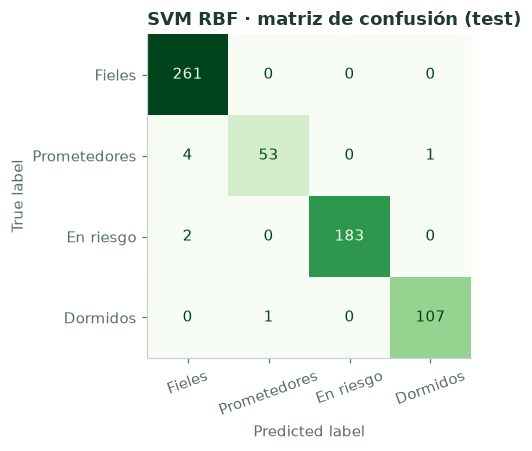

In [12]:
fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_te.map(G.NOMBRE),
    pd.Series(busqueda.predict(X_te)).map(G.NOMBRE),
    labels=orden,
    cmap="Greens",
    colorbar=False,
    ax=ax,
)
ax.grid(False)
ax.set_title("SVM RBF · matriz de confusión (test)")
plt.setp(ax.get_xticklabels(), rotation=20)
fig.tight_layout()
G.guardar(fig, "02_confusion_svm")

El kernel RBF supera al lineal: las fronteras entre segmentos no son hiperplanos (por
ejemplo, *En riesgo* combina recencia media con tendencia baja). Los pocos errores están
entre segmentos vecinos, en clientes que están justo en la frontera.

**¿Es circular entrenar un clasificador sobre etiquetas de clustering?** Lo sería si se
usara para "validar" los segmentos. Aquí el objetivo es otro: tener una regla de asignación
fija y rápida para datos nuevos. Que el F1 sea alto confirma que el SVM reproduce fielmente
las definiciones de negocio y que puede reemplazar al clustering en producción.

### Confianza de cada asignación

El modelo final se reentrena con todos los hogares y se calibra (`CalibratedClassifierCV`)
para que cada asignación traiga una probabilidad: un cliente con baja confianza está en
transición entre segmentos.

In [13]:
svm = S.svm_final(
    X_ent, seg_ent, busqueda.best_params_["svm__C"], busqueda.best_params_["svm__gamma"]
)

## 5. En producción: ¿quién cambió de segmento entre septiembre y diciembre?

Con el SVM ya entrenado se recalculan las variables al 31-dic y se asigna el segmento de
cada hogar, sin volver a clusterizar.

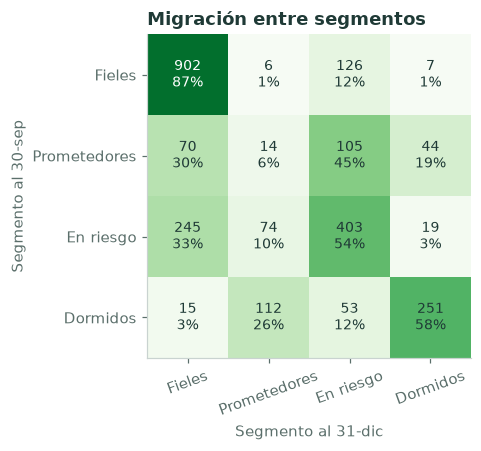

In [14]:
X_fin = S.matriz(f_fin)
seg_fin = pd.Series(svm.predict(X_fin), index=f_fin.index, name="segmento")
confianza = pd.Series(svm.predict_proba(X_fin).max(axis=1), index=f_fin.index, name="confianza")

mig = S.migracion(seg_ent, seg_fin).rename(index=G.NOMBRE, columns=G.NOMBRE)
fig, ax = plt.subplots(figsize=(5.6, 4.2))
pct = mig.div(mig.sum(axis=1), axis=0)
ax.imshow(pct.to_numpy(), cmap="Greens", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(
            j,
            i,
            f"{mig.iat[i, j]}\n{pct.iat[i, j]:.0%}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if pct.iat[i, j] > 0.6 else G.TINTA,
        )
ax.set_xticks(range(4), mig.columns, rotation=20)
ax.set_yticks(range(4), mig.index)
ax.set(xlabel="Segmento al 31-dic", ylabel="Segmento al 30-sep", title="Migración entre segmentos")
ax.grid(False)
fig.tight_layout()
G.guardar(fig, "02_migracion")

In [15]:
estables = np.trace(mig.to_numpy()) / mig.to_numpy().sum()
fieles_a_riesgo = mig.loc["Fieles", "En riesgo"]
nuevos = len(f_fin.index.difference(f_ent.index))
print(f"Mantienen su segmento: {estables:.0%}")
print(
    f"Fieles que pasaron a En riesgo: {fieles_a_riesgo}  ← lista concreta para una campaña de retención"
)
print(f"Hogares nuevos entre oct y dic (sin segmento previo): {nuevos}")
print(
    f"Confianza media de la asignación: {confianza.mean():.1%} (mínima {confianza.min():.0%}); "
    f"{(confianza < 0.95).sum()} hogares por debajo del 95 % → revisar a mano"
)

Mantienen su segmento: 64%
Fieles que pasaron a En riesgo: 126  ← lista concreta para una campaña de retención
Hogares nuevos entre oct y dic (sin segmento previo): 23
Confianza media de la asignación: 98.1% (mínima 90%); 219 hogares por debajo del 95 % → revisar a mano


**Lo que dice la migración:**

- Los *Fieles* son estables (87 % se mantiene), pero 126 empiezan a bajar el ritmo: es la
  lista con más valor en juego para una campaña de retención.
- Los *Prometedores* son el segmento más volátil: solo el 6 % sigue siéndolo tres meses
  después. El 30 % se consolida como *Fiel*, pero el 45 % se enfría y pasa a *En riesgo*.
  El momento de actuar con ellos son sus primeras semanas.
- Uno de cada cuatro *Dormidos* (26 %) se reactiva y aparece como *Prometedor*.

La confianza media (98,1 %) es casi igual al acierto del SVM en test (98,7 %): la calibración es
coherente. Los hogares con menos confianza son los que están en la frontera entre dos
segmentos.

**Control de cordura.** Si al 31-dic se volviera a clusterizar desde cero, ¿saldrían grupos
parecidos? El acuerdo con el SVM mide cuánto se han desplazado los datos.

In [16]:
refit = S.Segmentador(k=4).fit(f_fin).predict(f_fin)
print(
    f"ARI SVM vs K-Means reajustado: {adjusted_rand_score(refit, seg_fin):.3f}"
    f" · coincidencia de etiquetas: {(refit == seg_fin).mean():.0%}"
)

ARI SVM vs K-Means reajustado: 0.761 · coincidencia de etiquetas: 90%


## 6. Guardar resultados

Los segmentos del 31-dic (con su confianza) y los modelos se guardan para el notebook 04,
que los exporta al dashboard.

In [17]:
MODELOS.mkdir(parents=True, exist_ok=True)
joblib.dump({"segmentador": segmentador, "svm": svm}, MODELOS / "segmentacion.joblib")
pd.concat([seg_fin, confianza], axis=1).to_parquet(PROCESADOS / "segmentos_fin.parquet")
G.guardar_metricas(
    "segmentacion",
    {
        "k": 4,
        "silhouette": float(evaluacion.loc[4, "silhouette"]),
        "ari_bootstrap_medio": float(estab[4].mean()),
        "svm_rbf_f1_macro_test": float(comparacion["SVM RBF"]),
        "svm_lineal_f1_macro_test": float(comparacion["SVM lineal"]),
        "svm_C": float(busqueda.best_params_["svm__C"]),
        "svm_gamma": busqueda.best_params_["svm__gamma"],
        "mantienen_segmento": float(estables),
        "hogares_por_segmento_fin": seg_fin.value_counts()
        .reindex(S.SEGMENTOS)
        .astype(int)
        .to_dict(),
    },
)
seg_fin.map(G.NOMBRE).value_counts().reindex(orden).to_frame("hogares al 31-dic")

,hogares al 31-dic
segmento,
Fieles,1232
Prometedores,219
En riesgo,687
Dormidos,331


## Conclusiones

- Cuatro segmentos estables y con lectura de negocio: **Fieles, Prometedores, En riesgo, Dormidos**.
- El SVM RBF reproduce las definiciones con F1 macro ≈ 0,98 en test (el lineal se queda en ≈ 0,93)
  y asigna clientes nuevos sin re-clusterizar.
- La matriz de migración convierte el modelo en acciones: qué clientes fieles empiezan a
  irse y qué dormidos se están reactivando.